In [1]:
# ---- setup -----------------------------------------------------------------
import os, sys, glob, json, time
from pathlib import Path
NB_START = time.time()

CODE_DIR = Path("/kaggle/working/code"); CODE_DIR.mkdir(parents=True, exist_ok=True)
CACHE_DIR = sorted(d for d in glob.glob("/kaggle/input/**/m4raw_cache", recursive=True)
                   if os.path.isdir(os.path.join(d, "train")))[0]
print("cache:", CACHE_DIR)
print(json.loads(Path(CACHE_DIR, "manifest.json").read_text())["splits"])

cache: /kaggle/input/datasets/mahimasunilbachhav/m4raw-sgf-cache/m4raw_cache
{'train': {'pair_volumes': 384, 'slices': 6912, 'subjects': 128}, 'val': {'pair_volumes': 90, 'slices': 1620, 'subjects': 30}}


In [2]:
%%writefile /kaggle/working/code/sgf_train.py
"""
Week-2 toolkit for reproducing SGF-MRI on M4Raw (T1 reference -> T2 target).

Contents
  * models      : Bicubic / zero-filled baseline, single- and multi-contrast U-Net
  * train()     : L1 loss, Adam 2e-4, StepLR(40, 0.1), batch 4  (SGF-MRI Sec. 4.1)
                  checkpoint every epoch, auto-resume, stops cleanly before Kaggle's 12 h limit
  * evaluate()  : PSNR / SSIM per volume, exactly as DCAMSR/fastMRI compute them
  * profile()   : parameters, peak GPU memory, inference time per slice

Every model uses DCAMSR's call signature  model(lr, ref, ref_down)
    lr       (B,1,h,w)  degraded T2 (LR image for SR, zero-filled image for reconstruction)
    ref      (B,1,H,W)  fully sampled T1
    ref_down (B,1,h,w)  T1 degraded the same way as the input (SR only)
and returns (B,1,H,W).  DCAMSR and SGF-MRI will plug in later with no other changes.
"""
from __future__ import annotations

import csv
import glob
import json
import math
import os
import random
import shutil
import time
from dataclasses import asdict, dataclass, field
from pathlib import Path
from typing import Optional

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

from m4raw_dataset import M4RawPairs
from m4raw_prep import fft2c, ifft2c


# =========================================================================== #
# Locating the cache on Kaggle
# =========================================================================== #
def find_cache_dir() -> str:
    hits = sorted(glob.glob("/kaggle/input/**/m4raw_cache", recursive=True))
    hits = [h for h in hits if os.path.isdir(os.path.join(h, "train"))]
    if not hits:
        raise FileNotFoundError("m4raw_cache not found: Add Input -> Your Datasets -> your cache dataset")
    return hits[0]


# =========================================================================== #
# Dataset: same as M4RawPairs, plus a choice of which axis the recon mask drops
# =========================================================================== #
class M4RawTask(M4RawPairs):
    """
    mask_axis = -1 : drop k-space columns (fastMRI convention, default in m4raw_dataset)
    mask_axis = -2 : drop k-space rows    (the SGF-MRI paper text says "rows")
    """

    def __init__(self, *a, mask_axis: int = -1, preload: bool = False, **kw):
        super().__init__(*a, **kw)
        assert mask_axis in (-1, -2)
        self.mask_axis = mask_axis
        self._ram = None
        if preload:
            self._preload()

    # ---- optional: hold the needed arrays in RAM ---------------------------
    # Reading every slice from the HDF5 files inside the data-loader workers made
    # RAM use creep up for hours and finally got the run killed (commit log, 29 Oct);
    # as RAM filled, the OS dropped its file cache and epochs slowed from 2.4 to 23 min.
    # Preloading reads each file ONCE, sequentially; workers then only slice arrays
    # (forked workers share these pages; nothing is copied).
    def _needed_keys(self):
        keys = ["tar_hr", "ref_hr"]
        if self.task == "sr":
            keys += [f"tar_lr{self.scale}", f"ref_lr{self.scale}"]
        return keys

    def _preload(self):
        import h5py
        t0 = time.time()
        keys = self._needed_keys()
        total = len(self.examples)
        self._row, start = {}, 0
        with h5py.File(self.files[0], "r") as hf:
            shapes = {k: hf[k].shape[1:] for k in keys}
        self._ram = {k: np.empty((total,) + shapes[k], np.float32) for k in keys}   # allocated once, filled in place
        for f in self.files:
            with h5py.File(f, "r") as hf:
                n = int(hf.attrs["num_slices"])
                for k in keys:
                    hf[k].read_direct(self._ram[k], np.s_[:n], np.s_[start:start + n])
            self._row[f] = start
            start += n
        assert start == total
        gb = sum(a.nbytes for a in self._ram.values()) / 2**30
        print(f"[{_now()}] preloaded {len(self.files)} volumes / {total} slices ({gb:.1f} GB) "
              f"in {time.time() - t0:.0f} s", flush=True)

    def __getitem__(self, i):
        if self._ram is None:
            return super().__getitem__(i)
        from m4raw_dataset import _norm
        path, s = self.examples[i]
        r = self._row[path] + s
        tar_hr = self._ram["tar_hr"][r]
        ref_hr = self._ram["ref_hr"][r]
        if self.task == "sr":
            tar_in = self._ram[f"tar_lr{self.scale}"][r]
            ref_in = self._ram[f"ref_lr{self.scale}"][r]
            mask = np.ones(1, np.float32)
        else:
            tar_in, mask = self._zero_filled(tar_hr, path.stem)
            ref_in = ref_hr
        # identical to M4RawPairs.__getitem__ (DCAMSR normalisation; ddof=1 like torch .std())
        mean, std = tar_in.mean(), tar_in.std(ddof=1)
        rmean, rstd = ref_in.mean(), ref_in.std(ddof=1)
        sample = {"input": _norm(tar_in, mean, std), "target": _norm(tar_hr, mean, std),
                  "ref": _norm(ref_hr, rmean, rstd), "ref_in": _norm(ref_in, rmean, rstd),
                  "mask": mask, "mean": np.float32(mean), "std": np.float32(std),
                  "fname": path.stem, "slice": s}
        for k in ("input", "target", "ref", "ref_in", "mask"):
            sample[k] = torch.from_numpy(sample[k])
        return sample

    def _zero_filled(self, img, name):
        from m4raw_dataset import _seed_from_name
        seed = _seed_from_name(name) if self.deterministic else None
        n = img.shape[self.mask_axis]
        mask = self.mask_func(n, seed)
        m2d = mask[None, :] if self.mask_axis == -1 else mask[:, None]
        k = fft2c(img.astype(np.complex64)) * m2d
        return np.abs(ifft2c(k)).astype(np.float32), mask


def worker_init_fn(_):
    """Give every DataLoader worker its own random-mask stream.
    Without this, all workers start from the same copied RandomState and
    produce identical 'random' masks (a classic numpy + DataLoader bug)."""
    info = torch.utils.data.get_worker_info()
    ds = info.dataset
    seed = info.seed % 2**32
    np.random.seed(seed)
    random.seed(seed)
    if hasattr(ds, "mask_func"):
        ds.mask_func.rng = np.random.RandomState(seed)


def make_dataset(cache_dir, split, cfg: "Config", max_pairs=None, preload=None):
    preload = getattr(cfg, "preload", False) if preload is None else preload
    return M4RawTask(cache_dir, split, task=cfg.task, scale=cfg.scale, accel=cfg.accel,
                     mask_axis=cfg.mask_axis, max_pairs=max_pairs, preload=preload)


# =========================================================================== #
# Models
# =========================================================================== #
def upsample_to(x, hw, mode="bicubic"):
    if tuple(x.shape[-2:]) == tuple(hw):
        return x
    return F.interpolate(x, size=hw, mode=mode, align_corners=False)


class Bicubic(nn.Module):
    """
    No learning. SR: bicubic upsampling of the LR image. Recon: the zero-filled image itself.

    DCAMSR makes LR images by cropping the centre of k-space with an orthonormal FFT,
    which leaves them `scale` times BRIGHTER than the HR image (2x / 4x). Trained
    networks learn this (DCAMSR and SGF-MRI were trained on exactly this data), but a
    plain interpolation cannot, so evaluate() divides this model's de-normalised output
    by `intensity_divisor`.
    """

    def __init__(self, scale: int = 1, **_):
        super().__init__()
        self.intensity_divisor = float(scale)
        self.dummy = nn.Parameter(torch.zeros(()), requires_grad=False)

    def forward(self, lr, ref, ref_down=None):
        return upsample_to(lr, ref.shape[-2:])


def _norm_layer(c, norm):
    return nn.InstanceNorm2d(c) if norm == "instance" else nn.Identity()


class ConvBlock(nn.Module):
    def __init__(self, cin, cout, norm="none"):
        super().__init__()
        bias = norm == "none"
        self.net = nn.Sequential(
            nn.Conv2d(cin, cout, 3, padding=1, bias=bias), _norm_layer(cout, norm), nn.LeakyReLU(0.2, True),
            nn.Conv2d(cout, cout, 3, padding=1, bias=bias), _norm_layer(cout, norm), nn.LeakyReLU(0.2, True))

    def forward(self, x):
        return self.net(x)


class UNet(nn.Module):
    """
    fastMRI-style U-Net (conv-LeakyReLU x2, avg-pool down, transpose-conv up).
    norm="none" by default: with DCAMSR's data the model must recover each image's
    absolute brightness level (LR is `scale`x brighter than HR), and InstanceNorm
    erases exactly that information (tested: single-contrast SR stalls with it).
    """

    def __init__(self, in_chans=1, out_chans=1, chans=32, num_pools=3, norm="none"):
        super().__init__()
        self.num_pools = num_pools
        self.down = nn.ModuleList([ConvBlock(in_chans, chans, norm)])
        c = chans
        for _ in range(num_pools - 1):
            self.down.append(ConvBlock(c, c * 2, norm)); c *= 2
        self.bottom = ConvBlock(c, c * 2, norm)
        self.up_t, self.up_c = nn.ModuleList(), nn.ModuleList()
        for _ in range(num_pools):
            self.up_t.append(nn.Sequential(nn.ConvTranspose2d(c * 2, c, 2, stride=2, bias=norm == "none"),
                                           _norm_layer(c, norm), nn.LeakyReLU(0.2, True)))
            self.up_c.append(ConvBlock(c * 2, c, norm)); c //= 2
        self.out = nn.Conv2d(chans, out_chans, 1)

    def forward(self, x):
        h, w = x.shape[-2:]
        m = 2 ** self.num_pools                      # pad so every pooling divides evenly
        ph, pw = (-h) % m, (-w) % m
        x = F.pad(x, (pw // 2, pw - pw // 2, ph // 2, ph - ph // 2), mode="reflect")
        skips = []
        for blk in self.down:
            x = blk(x); skips.append(x); x = F.avg_pool2d(x, 2)
        x = self.bottom(x)
        for t, c in zip(self.up_t, self.up_c):
            x = c(torch.cat([t(x), skips.pop()], 1))
        x = self.out(x)
        return x[..., ph // 2: ph // 2 + h, pw // 2: pw // 2 + w]


class UNetRestorer(nn.Module):
    """
    Upsample the degraded T2 to full size, then predict a residual correction.
      use_ref=False : single-contrast baseline (T2 only)
      use_ref=True  : plain multi-contrast baseline (T1 concatenated as a 2nd channel)
    The pair (single vs multi) is the "does the reference help?" first row of Fig. 5a.
    """

    def __init__(self, use_ref=False, chans=32, num_pools=3, norm="none", **_):
        super().__init__()
        self.use_ref = use_ref
        self.unet = UNet(in_chans=2 if use_ref else 1, chans=chans, num_pools=num_pools, norm=norm)

    def forward(self, lr, ref, ref_down=None):
        up = upsample_to(lr, ref.shape[-2:])
        inp = torch.cat([up, ref], 1) if self.use_ref else up
        return up + self.unet(inp)


MODELS = {
    "bicubic": lambda cfg: Bicubic(cfg.scale if cfg.task == "sr" else 1),
    "unet_single": lambda cfg: UNetRestorer(False, cfg.chans, cfg.num_pools, cfg.norm),
    "unet_multi": lambda cfg: UNetRestorer(True, cfg.chans, cfg.num_pools, cfg.norm),
    # Week 3: "dcamsr": ..., Week 4-5: "sgf_mri": ...
}


def build_model(cfg: "Config") -> nn.Module:
    if cfg.model not in MODELS:
        raise KeyError(f"unknown model {cfg.model!r}; choose from {list(MODELS)}")
    return MODELS[cfg.model](cfg)


def count_params(model) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


# =========================================================================== #
# Config
# =========================================================================== #
@dataclass
class Config:
    run_name: str = "unet_single_sr4"
    model: str = "unet_single"
    task: str = "sr"                 # "sr" or "recon"
    scale: int = 4                   # SR factor (2 or 4)
    accel: int = 4                   # recon acceleration (4 or 8)
    mask_axis: int = -1              # recon: -1 columns (fastMRI) / -2 rows (paper text)
    chans: int = 32
    num_pools: int = 3               # paper: "encoder-decoder has 3 layers"
    norm: str = "none"               # U-Net normalisation: "none" | "instance"
    epochs: int = 50                 # not given in the paper; DCAMSR's train.py uses 50
    batch_size: int = 4              # paper
    lr: float = 2e-4                 # paper
    lr_step: int = 40                # paper
    lr_gamma: float = 0.1            # paper
    num_workers: int = 4             # training data-loader processes
    eval_workers: int = 2            # evaluation data-loader processes (kept small: they run beside the training ones)
    amp: bool = True                 # mixed precision on GPU (~2x faster, less memory)
    multi_gpu: bool = False          # DataParallel over 2 GPUs. Slower than 1 GPU for this small model;
                                     # better: train two models at once, one per GPU (notebook 02, step C)
    log_every: int = 200             # progress + RAM/GPU line every N iterations
    preload: bool = True             # hold this task's arrays in RAM (~4.7 GB for SR x4, train + test)
    seed: int = 42
    val_every: int = 5               # full test-set evaluation every N epochs (+ last epoch)
    time_budget_h: float = 11.0      # stop cleanly before Kaggle's 12 h session limit
    max_train_pairs: Optional[int] = None   # small numbers = quick smoke test
    max_val_pairs: Optional[int] = None
    out_root: str = "/kaggle/working/runs"

    @property
    def out_dir(self) -> Path:
        return Path(self.out_root) / self.run_name

    def describe(self):
        deg = f"SR x{self.scale}" if self.task == "sr" else f"recon {self.accel}x (mask axis {self.mask_axis})"
        return f"{self.model} | {deg}"


# =========================================================================== #
# Evaluation (DCAMSR / fastMRI protocol)
# =========================================================================== #
def _volume_scores(gt, pred):
    """fastmri/evaluate.py: data_range = volume max; SSIM averaged over slices."""
    from skimage.metrics import peak_signal_noise_ratio, structural_similarity
    dr = float(gt.max())
    p = peak_signal_noise_ratio(gt, pred, data_range=dr)
    s = float(np.mean([structural_similarity(g, q, data_range=dr) for g, q in zip(gt, pred)]))
    return p, s


@torch.no_grad()
def evaluate(model, dataset, device, batch_size=8, num_workers=4, amp=True, keep_examples=0):
    """
    Runs the whole split in order, rebuilds each volume, de-normalises with
    x * std + mean (the GT is the de-normalised, [-6,6]-clipped target, exactly
    what DCAMSR's validation_step compares against), and scores per volume.
    Returns metrics dict (+ a list of example slices if keep_examples > 0).
    """
    model.eval()
    loader = DataLoader(dataset, batch_size=batch_size, shuffle=False,
                        num_workers=num_workers, pin_memory=device.type == "cuda")
    use_amp = amp and device.type == "cuda"
    n_slices = {}
    for path, s in dataset.examples:
        n_slices[path.stem] = n_slices.get(path.stem, 0) + 1
    psnrs, ssims, names, examples = [], [], [], []
    cur, preds, gts = None, [], []

    def flush():
        if cur is None:
            return
        p, s = _volume_scores(np.stack(gts), np.stack(preds))
        psnrs.append(p); ssims.append(s); names.append(cur)

    for b in loader:
        lr = b["input"].unsqueeze(1).to(device)
        ref = b["ref"].unsqueeze(1).to(device)
        ref_in = b["ref_in"].unsqueeze(1).to(device)
        with torch.autocast("cuda", dtype=torch.float16, enabled=use_amp):
            out = model(lr, ref, ref_in)
        out = out.float().squeeze(1).cpu().numpy()
        mean = b["mean"].numpy()[:, None, None]
        std = b["std"].numpy()[:, None, None]
        out = (out * std + mean) / getattr(model, "intensity_divisor", 1.0)
        tgt = b["target"].numpy() * std + mean
        for i, name in enumerate(b["fname"]):
            if name != cur:
                flush(); cur, preds, gts = name, [], []
            preds.append(out[i]); gts.append(tgt[i])
            if len(examples) < keep_examples and int(b["slice"][i]) == n_slices[name] // 2:
                examples.append({"name": name, "input": b["input"][i].numpy() * std[i] + mean[i],
                                 "output": out[i], "target": tgt[i], "ref": b["ref"][i].numpy()})
    flush()
    res = {"psnr": float(np.mean(psnrs)), "psnr_std": float(np.std(psnrs)),
           "ssim": float(np.mean(ssims)), "ssim_std": float(np.std(ssims)),
           "n_volumes": len(psnrs)}
    return (res, examples) if keep_examples else res


# =========================================================================== #
# Checkpointing
# =========================================================================== #
def _save(state, path: Path):
    tmp = path.with_suffix(".tmp")
    torch.save(state, tmp)
    os.replace(tmp, path)                     # atomic: a crash never leaves a broken file


def _bring_previous_run(cfg: Config):
    """If this run is not in /kaggle/working, copy it from an attached previous version."""
    if (cfg.out_dir / "last.pt").exists():
        return
    hits = sorted(glob.glob(f"/kaggle/input/**/runs/{cfg.run_name}/last.pt", recursive=True))
    if hits:
        src = Path(hits[-1]).parent
        shutil.copytree(src, cfg.out_dir, dirs_exist_ok=True)
        print(f"[resume] copied previous run from {src}")


# =========================================================================== #
# Training
# =========================================================================== #
def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)


def resources(device=None) -> str:
    """One short line: system RAM, this process's RAM, GPU memory, free disk."""
    parts = []
    try:
        import psutil
        vm = psutil.virtual_memory()
        rss = psutil.Process().memory_info().rss
        kids = sum(c.memory_info().rss for c in psutil.Process().children(recursive=True))
        parts.append(f"RAM {vm.used/2**30:.1f}/{vm.total/2**30:.0f} GB ({vm.percent:.0f}%)")
        parts.append(f"proc {rss/2**30:.1f} GB + workers {kids/2**30:.1f} GB")
    except Exception:
        pass
    if device is not None and device.type == "cuda":
        parts.append(f"GPU{torch.cuda.current_device()} {torch.cuda.memory_allocated()/2**30:.2f} GB "
                     f"(peak {torch.cuda.max_memory_allocated()/2**30:.2f})")
    try:
        parts.append(f"disk free {shutil.disk_usage('/kaggle/working' if os.path.isdir('/kaggle/working') else '.').free/2**30:.0f} GB")
    except Exception:
        pass
    return " | ".join(parts)


def _now():
    return time.strftime("%H:%M:%S")


def _arm_watchdog(minutes=30):
    """If nothing is logged for `minutes`, dump every thread's stack to the log (diagnoses hangs)."""
    import faulthandler, sys
    faulthandler.cancel_dump_traceback_later()
    faulthandler.dump_traceback_later(minutes * 60, repeat=True, file=sys.stderr)


def train(cfg: Config, cache_dir: str):
    import faulthandler, sys, traceback
    faulthandler.enable(file=sys.stderr)        # a hard crash (segfault) still prints where it happened
    t_start = time.time()
    seed_everything(cfg.seed)
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    if device.type == "cuda":
        torch.backends.cudnn.benchmark = True
    cfg.out_dir.mkdir(parents=True, exist_ok=True)
    _bring_previous_run(cfg)

    train_ds = make_dataset(cache_dir, "train", cfg, cfg.max_train_pairs)
    val_ds = make_dataset(cache_dir, "val", cfg, cfg.max_val_pairs)
    g = torch.Generator(); g.manual_seed(cfg.seed)
    train_dl = DataLoader(train_ds, batch_size=cfg.batch_size, shuffle=True, drop_last=True,
                          num_workers=cfg.num_workers, pin_memory=device.type == "cuda",
                          worker_init_fn=worker_init_fn, generator=g,
                          persistent_workers=cfg.num_workers > 0)

    model = build_model(cfg).to(device)
    n_params = count_params(model)
    net = nn.DataParallel(model) if (cfg.multi_gpu and torch.cuda.device_count() > 1) else model
    opt = torch.optim.Adam(model.parameters(), lr=cfg.lr, betas=(0.9, 0.999), eps=1e-8, weight_decay=0.0)
    sched = torch.optim.lr_scheduler.StepLR(opt, cfg.lr_step, cfg.lr_gamma)
    use_amp = cfg.amp and device.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)

    start_epoch, best, history = 0, -math.inf, []
    last = cfg.out_dir / "last.pt"
    if last.exists():
        ck = torch.load(last, map_location=device, weights_only=False)
        model.load_state_dict(ck["model"]); opt.load_state_dict(ck["optim"])
        sched.load_state_dict(ck["sched"]); scaler.load_state_dict(ck["scaler"])
        start_epoch, best, history = ck["epoch"] + 1, ck["best_psnr"], ck["history"]
        print(f"[resume] continuing from epoch {start_epoch} (best PSNR so far {best:.3f})")
    (cfg.out_dir / "config.json").write_text(json.dumps(asdict(cfg), indent=2))

    gpu_name = torch.cuda.get_device_name(device) if device.type == "cuda" else "cpu"
    print(f"[{_now()}] {cfg.run_name}: {cfg.describe()} | params {n_params/1e6:.2f} M | {gpu_name}"
          f"{' x' + str(torch.cuda.device_count()) if isinstance(net, nn.DataParallel) else ''} | "
          f"train {len(train_ds)} slices ({len(train_dl)} it/epoch) | test {len(val_ds)} slices | "
          f"budget {cfg.time_budget_h:.1f} h", flush=True)
    print(f"[{_now()}] {resources(device)}", flush=True)
    if start_epoch >= cfg.epochs:
        print("already finished"); return history

    epoch_times = []
    _arm_watchdog()
    for epoch in range(start_epoch, cfg.epochs):
        t0 = time.time()
        net.train()
        tot, n = 0.0, 0
        t_last, t_wait = time.time(), 0.0
        t_fetch = time.time()
        for it, b in enumerate(train_dl):
            t_wait += time.time() - t_fetch      # time spent waiting for data
            lr_img = b["input"].unsqueeze(1).to(device, non_blocking=True)
            ref = b["ref"].unsqueeze(1).to(device, non_blocking=True)
            ref_in = b["ref_in"].unsqueeze(1).to(device, non_blocking=True)
            tgt = b["target"].unsqueeze(1).to(device, non_blocking=True)
            with torch.autocast("cuda", dtype=torch.float16, enabled=use_amp):
                out = net(lr_img, ref, ref_in)
            loss = F.l1_loss(out.float(), tgt)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt); scaler.update()
            if not torch.isfinite(loss):
                raise FloatingPointError(f"loss became {loss.item()} at epoch {epoch} iter {it}")
            tot += loss.item(); n += 1
            if (it + 1) % cfg.log_every == 0 or it == 0:
                k = 1 if it == 0 else cfg.log_every
                dt = time.time() - t_last
                print(f"[{_now()}] ep {epoch:3d} it {it+1:5d}/{len(train_dl)} loss {loss.item():.4f} | "
                      f"{dt/k:.3f} s/it ({100*t_wait/max(dt,1e-9):.0f}% waiting for data) | {resources(device)}",
                      flush=True)
                t_last, t_wait = time.time(), 0.0
                _arm_watchdog()
            t_fetch = time.time()
        lr_used = opt.param_groups[0]["lr"]
        sched.step()
        rec = {"epoch": epoch, "lr": lr_used, "train_l1": tot / max(n, 1),
               "train_min": (time.time() - t0) / 60}

        # Save the epoch FIRST, so a problem during evaluation can never lose the training.
        history.append(rec)
        _save({"model": model.state_dict(), "optim": opt.state_dict(), "sched": sched.state_dict(),
               "scaler": scaler.state_dict(), "epoch": epoch, "best_psnr": best,
               "history": history, "cfg": asdict(cfg)}, last)
        _write_log(history, cfg.out_dir / "log.csv")

        do_val = (epoch + 1) % cfg.val_every == 0 or epoch + 1 == cfg.epochs
        if do_val:
            tv = time.time()
            print(f"[{_now()}] ep {epoch:3d} evaluating on {len(val_ds)} test slices ... | {resources(device)}",
                  flush=True)
            try:
                m = evaluate(model, val_ds, device, num_workers=cfg.eval_workers, amp=cfg.amp)
                rec.update({k: m[k] for k in ("psnr", "psnr_std", "ssim", "ssim_std")})
                if m["psnr"] > best:
                    best = m["psnr"]
                    _save({"model": model.state_dict(), "epoch": epoch, "metrics": m, "cfg": asdict(cfg)},
                          cfg.out_dir / "best.pt")
            except Exception as e:                # log it and keep training
                rec["val_error"] = f"{type(e).__name__}: {e}"
                print(f"[{_now()}] EVALUATION FAILED (training continues):", flush=True)
                traceback.print_exc()
            rec["val_min"] = (time.time() - tv) / 60
            if device.type == "cuda":
                torch.cuda.empty_cache()
            _save({"model": model.state_dict(), "optim": opt.state_dict(), "sched": sched.state_dict(),
                   "scaler": scaler.state_dict(), "epoch": epoch, "best_psnr": best,
                   "history": history, "cfg": asdict(cfg)}, last)
            _write_log(history, cfg.out_dir / "log.csv")
            _arm_watchdog()

        epoch_times.append(time.time() - t0)
        msg = f"[{_now()}] epoch {epoch:3d} done | L1 {rec['train_l1']:.4f} | {epoch_times[-1]/60:.1f} min"
        if "psnr" in rec:
            msg += (f" | test PSNR {rec['psnr']:.2f} SSIM {rec['ssim']:.4f} (best {best:.2f}) "
                    f"| eval {rec['val_min']:.1f} min")
        print(msg + f" | total {(time.time()-t_start)/3600:.2f} h", flush=True)

        elapsed = time.time() - t_start
        if epoch + 1 < cfg.epochs and elapsed + 1.5 * max(epoch_times[-3:]) > cfg.time_budget_h * 3600:
            print(f"[{_now()}] [time budget] stopping after epoch {epoch} ({elapsed/3600:.1f} h). "
                  f"Run again (attach this version's output as input) to resume.", flush=True)
            break
    import faulthandler
    faulthandler.cancel_dump_traceback_later()
    return history


def _write_log(history, path):
    keys = sorted({k for r in history for k in r}, key=lambda k: (k != "epoch", k))
    with open(path, "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=keys); w.writeheader(); w.writerows(history)


def load_for_eval(cfg: Config, which="best", device=None):
    device = device or torch.device("cuda" if torch.cuda.is_available() else "cpu")
    model = build_model(cfg).to(device)
    ck = torch.load(cfg.out_dir / f"{which}.pt", map_location=device, weights_only=False)
    model.load_state_dict(ck["model"])
    return model, ck.get("epoch")


# =========================================================================== #
# Efficiency (paper Sec. 4.4: memory / time / parameters)
# =========================================================================== #
@torch.no_grad()
def profile(model, cfg: Config, hw=(256, 256), repeats=50):
    device = next(model.parameters()).device
    H, W = hw
    h, w = (H // cfg.scale, W // cfg.scale) if cfg.task == "sr" else (H, W)
    lr = torch.randn(1, 1, h, w, device=device)
    ref = torch.randn(1, 1, H, W, device=device)
    ref_in = torch.randn(1, 1, h, w, device=device)
    model.eval()
    for _ in range(5):
        model(lr, ref, ref_in)
    if device.type == "cuda":
        torch.cuda.synchronize(); torch.cuda.reset_peak_memory_stats()
    t = time.time()
    for _ in range(repeats):
        model(lr, ref, ref_in)
    if device.type == "cuda":
        torch.cuda.synchronize()
    out = {"params_M": count_params(model) / 1e6, "sec_per_slice": (time.time() - t) / repeats}
    if device.type == "cuda":
        out["peak_mem_MB"] = torch.cuda.max_memory_allocated() / 2**20
    return out


# =========================================================================== #
# Paper numbers (M4Raw rows of Tables 1 and 2) for side-by-side comparison
# =========================================================================== #
PAPER_M4RAW = {
    ("sr", 2):    {"SwinIR": (32.16, 0.777), "DCAMSR": (32.31, 0.779), "SGF-MRI": (32.42, 0.781)},
    ("sr", 4):    {"SwinIR": (29.73, 0.709), "DCAMSR": (30.48, 0.728), "SGF-MRI": (30.62, 0.731)},
    ("recon", 4): {"SwinIR": (29.12, 0.692), "DCAMSR": (29.62, 0.706), "SGF-MRI": (29.82, 0.716)},
    ("recon", 8): {"SwinIR": (27.93, 0.621), "DCAMSR": (28.09, 0.658), "SGF-MRI": (28.27, 0.666)},
}


def paper_key(cfg: Config):
    return (cfg.task, cfg.scale if cfg.task == "sr" else cfg.accel)


def append_result(row: dict, path="/kaggle/working/results.csv"):
    path = Path(path)
    rows = []
    if path.exists():
        with open(path) as f:
            rows = list(csv.DictReader(f))
    rows = [r for r in rows if not (r.get("run") == row["run"] and r.get("checkpoint") == row.get("checkpoint"))]
    rows.append({k: (f"{v:.4f}" if isinstance(v, float) else v) for k, v in row.items()})
    keys = list(dict.fromkeys(k for r in rows for k in r))
    with open(path, "w", newline="") as f:
        w = csv.DictWriter(f, fieldnames=keys); w.writeheader(); w.writerows(rows)


# =========================================================================== #
# Running training as separate processes (robust Kaggle commits)
# =========================================================================== #
EXIT_MEANING = {0: "finished OK", 1: "Python error (traceback in its log)",
                -9: "KILLED by the system - almost always out of RAM",
                137: "KILLED by the system - almost always out of RAM",
                -15: "terminated", -11: "crashed (segmentation fault)"}


def _tail(path, n=25):
    try:
        with open(path, "rb") as f:
            f.seek(0, 2); size = f.tell(); f.seek(max(0, size - 20000))
            return f.read().decode(errors="replace").splitlines()[-n:]
    except OSError:
        return []


def launch_jobs(jobs, cache_dir, code_dir, session_hours=11.0, poll_minutes=10, out_root=None):
    """
    Trains each Config in `jobs` in its OWN Python process, one GPU each (round-robin),
    all at the same time, and waits for them. Output of job X goes to runs/X/train.log.

    Why a separate process: if training crashes or is killed (e.g. out of memory),
    only that process dies; this notebook keeps running, reports the reason, and the
    Kaggle commit still finishes, so every checkpoint written so far is saved.
    Returns {run_name: exit_code}.
    """
    import subprocess, sys
    t0 = time.time()
    n_gpu = torch.cuda.device_count()
    cpus = os.cpu_count() or 2
    procs = {}
    for i, cfg in enumerate(jobs):
        if out_root:
            cfg.out_root = out_root
        cfg.num_workers = max(1, cpus // len(jobs))
        cfg.eval_workers = max(1, min(2, cfg.num_workers))
        cfg.time_budget_h = session_hours
        cfg.multi_gpu = False
        cfg.out_dir.mkdir(parents=True, exist_ok=True)
        _bring_previous_run(cfg)                      # resume files in place before logging starts
        cfg_path = cfg.out_dir / "launch_config.json"
        cfg_path.write_text(json.dumps(asdict(cfg), indent=2))
        env = dict(os.environ, PYTHONUNBUFFERED="1", MALLOC_ARENA_MAX="2",   # limits glibc memory fragmentation
                   PYTHONPATH=os.pathsep.join([str(code_dir), str(cache_dir), os.environ.get("PYTHONPATH", "")]))
        gpu = f"GPU {i % n_gpu}" if n_gpu else "CPU"
        if n_gpu:
            env["CUDA_VISIBLE_DEVICES"] = str(i % n_gpu)
        log_path = cfg.out_dir / "train.log"
        log = open(log_path, "a")
        log.write(f"\n===== launch {time.strftime('%Y-%m-%d %H:%M:%S')} on {gpu} =====\n"); log.flush()
        p = subprocess.Popen([sys.executable, "-u", str(Path(code_dir) / "sgf_train.py"),
                              "--config", str(cfg_path), "--cache", str(cache_dir)],
                             stdout=log, stderr=subprocess.STDOUT, env=env)
        procs[cfg.run_name] = (p, log_path, log)
        print(f"[{_now()}] started {cfg.run_name} on {gpu} | {cfg.describe()} | "
              f"{cfg.num_workers} data workers | log: {log_path}", flush=True)

    codes = {}
    try:
        while len(codes) < len(procs):
            deadline = time.time() + poll_minutes * 60
            while time.time() < deadline and len(codes) < len(procs):
                time.sleep(5)
                for name, (p, lp, lf) in procs.items():
                    if name not in codes and p.poll() is not None:
                        codes[name] = p.returncode; lf.close()
                        print(f"[{_now()}] {name} ended: exit {p.returncode} = "
                              f"{EXIT_MEANING.get(p.returncode, 'unexpected exit')}", flush=True)
            print(f"[{_now()}] --- status after {(time.time()-t0)/3600:.2f} h | {resources()}", flush=True)
            for name, (p, lp, lf) in procs.items():
                last = next((l for l in reversed(_tail(lp, 40)) if l.startswith("[")), "(no progress line yet)")
                state = "running" if name not in codes else f"ended ({codes[name]})"
                print(f"    {name:20s} {state:12s} {last[:170]}", flush=True)
    except KeyboardInterrupt:
        print("interrupted: stopping the training processes (checkpoints so far are kept)")
        for name, (p, lp, lf) in procs.items():
            if p.poll() is None:
                p.terminate()
        for name, (p, lp, lf) in procs.items():
            try:
                p.wait(timeout=60)
            except Exception:
                p.kill()
            codes.setdefault(name, p.returncode)

    for name, (p, lp, lf) in procs.items():
        if codes.get(name) != 0:
            print(f"\n===== last lines of {lp} =====")
            print("\n".join(_tail(lp, 40)))
    return codes


def _cli():
    import argparse, traceback
    ap = argparse.ArgumentParser(description="train one SGF-MRI reproduction run")
    ap.add_argument("--config", required=True)
    ap.add_argument("--cache", required=True)
    a = ap.parse_args()
    cfg = Config(**json.loads(Path(a.config).read_text()))
    try:
        train(cfg, a.cache)
        print(f"[{_now()}] [done] {cfg.run_name}", flush=True)
        return 0
    except Exception:
        traceback.print_exc()
        return 1


if __name__ == "__main__":
    raise SystemExit(_cli())

Writing /kaggle/working/code/sgf_train.py


In [3]:
sys.path.insert(0, CACHE_DIR)          # m4raw_dataset.py / m4raw_prep.py from the cache dataset
sys.path.insert(0, str(CODE_DIR))      # sgf_train.py
import importlib, torch, numpy as np, pandas as pd
import sgf_train as T; importlib.reload(T)
from sgf_train import Config, evaluate, load_for_eval, profile, append_result, PAPER_M4RAW, paper_key, launch_jobs

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("torch", torch.__version__, "| device:", DEVICE,
      *(torch.cuda.get_device_name(i) for i in range(torch.cuda.device_count())), "| CPUs:", os.cpu_count())
print(T.resources(DEVICE))
NUM_WORKERS = min(4, os.cpu_count())

torch 2.11.0+cu128 | device: cuda Tesla T4 Tesla T4 | CPUs: 4
RAM 1.1/31 GB (5%) | proc 0.6 GB + workers 0.0 GB | GPU0 0.00 GB (peak 0.00) | disk free 20 GB


In [4]:
DO_BASELINES = False
DO_SMOKE     = True      # ~5 min safety check before the long run; set False once it has passed in a commit
DO_TRAIN     = True
DO_EVAL      = True
SESSION_HOURS = 11.0     # Kaggle stops a session at 12 h; training stops cleanly before this

COMMON = dict(task="sr", scale=4, accel=4, mask_axis=-1, epochs=50, val_every=5)
JOBS = [
    Config(run_name="unet_single_sr4", model="unet_single", **COMMON),   # T2 only
    Config(run_name="unet_multi_sr4",  model="unet_multi",  **COMMON),   # T2 + T1 reference
]
for j in JOBS:
    print(j.run_name, "|", j.describe(), "->", j.out_dir)

unet_single_sr4 | unet_single | SR x4 -> /kaggle/working/runs/unet_single_sr4
unet_multi_sr4 | unet_multi | SR x4 -> /kaggle/working/runs/unet_multi_sr4


In [5]:
if DO_BASELINES:
    rows = []
    for task, f in [("sr", 2), ("sr", 4), ("recon", 4), ("recon", 8)]:
        c = Config(model="bicubic", task=task, scale=f, accel=f, mask_axis=JOBS[0].mask_axis)
        ds = T.make_dataset(CACHE_DIR, "val", c)
        m = evaluate(T.build_model(c).to(DEVICE), ds, DEVICE, num_workers=NUM_WORKERS)
        rows.append({"setting": f"{'bicubic' if task == 'sr' else 'zero-filled'} {task} x{f}",
                     "PSNR": round(m["psnr"], 2), "SSIM": round(m["ssim"], 4),
                     "paper SGF-MRI": PAPER_M4RAW[(task, f)]["SGF-MRI"][0]})
        append_result({"run": f"baseline_{task}{f}", "checkpoint": "-", "task": task, "factor": f,
                       **{k: m[k] for k in ("psnr", "psnr_std", "ssim", "ssim_std")}})
    display(pd.DataFrame(rows))

In [6]:
if DO_SMOKE:
    import shutil
    smoke = [Config(**{**T.asdict(j), "run_name": "_smoke_" + j.run_name, "epochs": 1, "val_every": 1,
                       "max_train_pairs": 8, "max_val_pairs": 4, "log_every": 20}) for j in JOBS]
    for s in smoke:
        shutil.rmtree(s.out_dir, ignore_errors=True)
    codes1 = launch_jobs(smoke, CACHE_DIR, CODE_DIR, session_hours=1.0, poll_minutes=1)
    for s in smoke:
        s.epochs = 2
    codes2 = launch_jobs(smoke, CACHE_DIR, CODE_DIR, session_hours=1.0, poll_minutes=1)
    ok = all(c == 0 for c in list(codes1.values()) + list(codes2.values()))
    for s in smoke:
        h = pd.read_csv(s.out_dir / "log.csv")
        print(f"{s.run_name}: epochs {list(h.epoch)} | L1 {[round(x, 3) for x in h.train_l1]} | "
              f"test PSNR {[round(x, 2) for x in h.psnr]}")
        ok = ok and list(h.epoch) == [0, 1]
        speed = [l for l in T._tail(s.out_dir / "train.log", 200) if " s/it " in l]
        if speed:
            print("   last speed line:", speed[-1][:160])
    print("\nSMOKE TEST", "PASSED" if ok else "FAILED: read the log lines printed above")
    for s in smoke:
        shutil.rmtree(s.out_dir, ignore_errors=True)
    if not ok:
        DO_TRAIN = False

[14:11:54] started _smoke_unet_single_sr4 on GPU 0 | unet_single | SR x4 | 2 data workers | log: /kaggle/working/runs/_smoke_unet_single_sr4/train.log
[14:11:54] started _smoke_unet_multi_sr4 on GPU 1 | unet_multi | SR x4 | 2 data workers | log: /kaggle/working/runs/_smoke_unet_multi_sr4/train.log
[14:12:34] _smoke_unet_single_sr4 ended: exit 0 = finished OK
[14:12:34] _smoke_unet_multi_sr4 ended: exit 0 = finished OK
[14:12:34] --- status after 0.01 h | RAM 1.3/31 GB (6%) | proc 0.6 GB + workers 0.0 GB | disk free 19 GB
    _smoke_unet_single_sr4 ended (0)    [14:12:30] [done] _smoke_unet_single_sr4
    _smoke_unet_multi_sr4 ended (0)    [14:12:27] [done] _smoke_unet_multi_sr4
[14:12:34] started _smoke_unet_single_sr4 on GPU 0 | unet_single | SR x4 | 2 data workers | log: /kaggle/working/runs/_smoke_unet_single_sr4/train.log
[14:12:34] started _smoke_unet_multi_sr4 on GPU 1 | unet_multi | SR x4 | 2 data workers | log: /kaggle/working/runs/_smoke_unet_multi_sr4/train.log
[14:13:04] _sm

In [7]:
if DO_TRAIN:
    remaining = SESSION_HOURS - (time.time() - NB_START) / 3600 - 0.4   # keep ~25 min for step D
    print(f"training budget for this session: {remaining:.1f} h")
    codes = launch_jobs(JOBS, CACHE_DIR, CODE_DIR, session_hours=remaining, poll_minutes=10)
    print("\nexit codes:", {k: f"{v} = {T.EXIT_MEANING.get(v, 'unexpected')}" for k, v in codes.items()})

training budget for this session: 10.6 h
[14:13:09] started unet_single_sr4 on GPU 0 | unet_single | SR x4 | 2 data workers | log: /kaggle/working/runs/unet_single_sr4/train.log
[14:13:09] started unet_multi_sr4 on GPU 1 | unet_multi | SR x4 | 2 data workers | log: /kaggle/working/runs/unet_multi_sr4/train.log
[14:23:09] --- status after 0.17 h | RAM 12.6/31 GB (42%) | proc 0.6 GB + workers 31.8 GB | disk free 19 GB
    unet_single_sr4      running      [14:23:07] ep   8 it   600/1728 loss 0.0495 | 0.035 s/it (1% waiting for data) | RAM 12.6/31 GB (42%) | proc 6.1 GB + workers 9.8 GB | GPU0 0.03 GB (peak 4.22) | disk fre
    unet_multi_sr4       running      [14:23:04] ep   8 it   200/1728 loss 0.0497 | 0.035 s/it (1% waiting for data) | RAM 12.6/31 GB (42%) | proc 6.1 GB + workers 9.8 GB | GPU0 0.03 GB (peak 4.23) | disk fre
[14:33:09] --- status after 0.33 h | RAM 12.6/31 GB (42%) | proc 0.6 GB + workers 31.8 GB | disk free 19 GB
    unet_single_sr4      running      [14:33:08] ep  1

[15:08:15] preloaded 90 volumes / 1620 slices (0.8 GB) in 10 s
unet_single_sr4 efficiency: {'params_M': 1.925, 'sec_per_slice': 0.0051, 'peak_mem_MB': 43.9771}


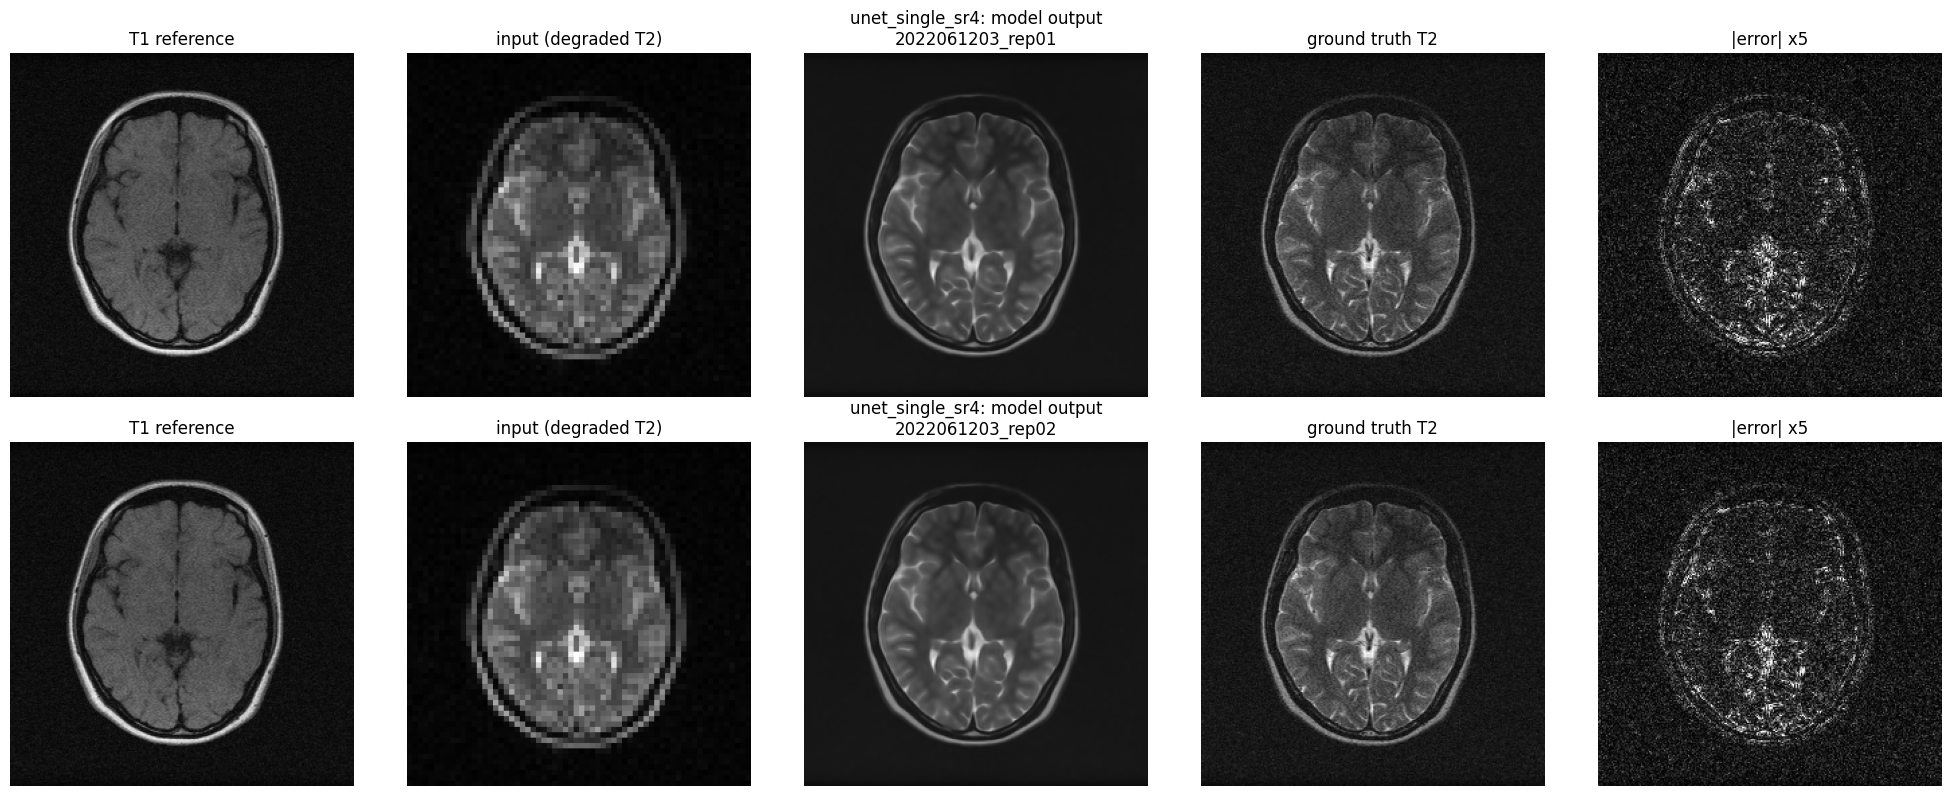

[15:08:53] preloaded 90 volumes / 1620 slices (0.8 GB) in 10 s
unet_multi_sr4 efficiency: {'params_M': 1.9253, 'sec_per_slice': 0.0052, 'peak_mem_MB': 44.478}


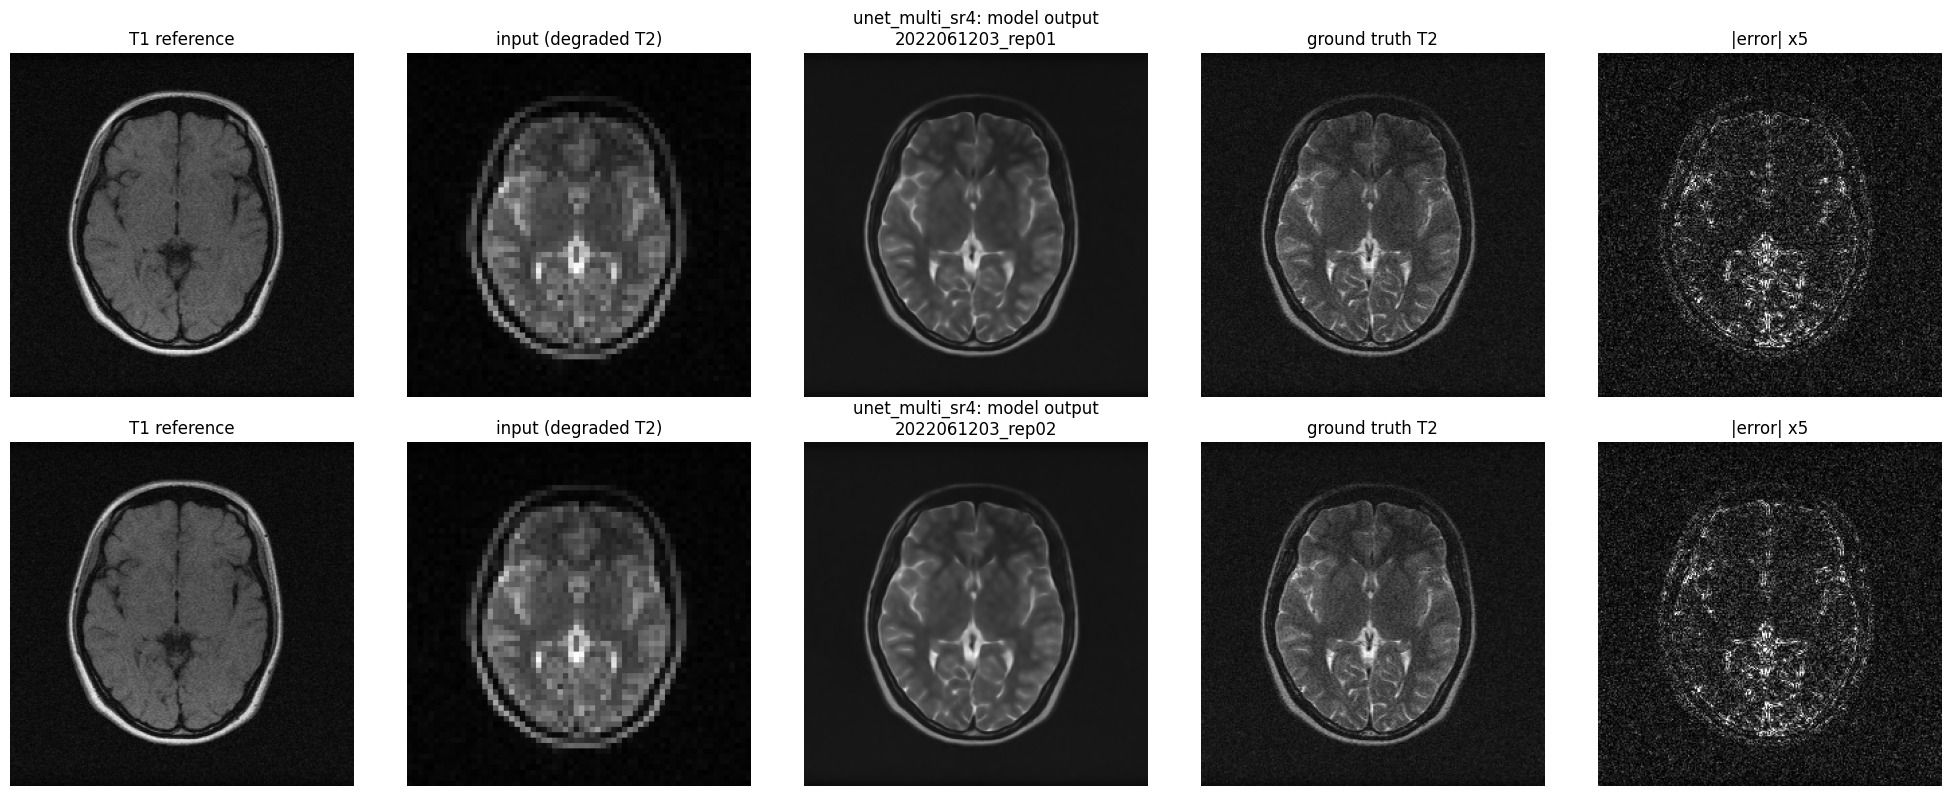

,run,checkpoint,PSNR,SSIM
0,unet_single_sr4,best (epoch 24),29.60 ± 0.61,0.7081 ± 0.022
1,unet_single_sr4,last (epoch 49),29.50 ± 0.61,0.7076 ± 0.022
2,unet_multi_sr4,best (epoch 44),30.28 ± 0.65,0.7256 ± 0.022
3,unet_multi_sr4,last (epoch 49),30.27 ± 0.65,0.7257 ± 0.022
4,paper: SwinIR,-,29.73,0.709
5,paper: DCAMSR,-,30.48,0.728
6,paper: SGF-MRI,-,30.62,0.731


In [8]:
if DO_EVAL:
    import matplotlib.pyplot as plt
    rows = []
    for cfg in JOBS:
        if not (cfg.out_dir / "last.pt").exists():
            print(f"{cfg.run_name}: no checkpoint yet"); continue
        ds = T.make_dataset(CACHE_DIR, "val", cfg)
        for which in ["best", "last"]:
            if not (cfg.out_dir / f"{which}.pt").exists():
                continue
            model, ep = load_for_eval(cfg, which, DEVICE)
            m, ex = evaluate(model, ds, DEVICE, num_workers=2, keep_examples=2)
            rows.append({"run": cfg.run_name, "checkpoint": f"{which} (epoch {ep})",
                         "PSNR": f"{m['psnr']:.2f} ± {m['psnr_std']:.2f}",
                         "SSIM": f"{m['ssim']:.4f} ± {m['ssim_std']:.3f}"})
            append_result({"run": cfg.run_name, "checkpoint": which, "epoch": ep, "task": cfg.task,
                           "factor": paper_key(cfg)[1], "model": cfg.model,
                           **{k: m[k] for k in ("psnr", "psnr_std", "ssim", "ssim_std")}})
        print(cfg.run_name, "efficiency:", {k: round(v, 4) for k, v in profile(model, cfg).items()})
        fig, axes = plt.subplots(len(ex), 5, figsize=(20, 4 * len(ex)), squeeze=False)
        for r, e in zip(axes, ex):
            hw = e["target"].shape
            inp = e["input"] if e["input"].shape == hw else np.kron(e["input"], np.ones((hw[0] // e["input"].shape[0],) * 2))
            vmax = e["target"].max()
            for a, img, t in zip(r, [e["ref"], inp, e["output"], e["target"], np.abs(e["output"] - e["target"])],
                                 ["T1 reference", "input (degraded T2)", "model output", "ground truth T2", "|error| x5"]):
                own_scale = t in ("T1 reference", "input (degraded T2)")   # LR input is x-scale brighter
                a.imshow(img * (5 if t.startswith("|") else 1), cmap="gray",
                         vmin=None if own_scale else 0, vmax=None if own_scale else vmax)
                a.set_title(f"{cfg.run_name}: {t}\n{e['name']}" if t == "model output" else t); a.axis("off")
        plt.tight_layout(); plt.show()
    key = paper_key(JOBS[0])
    for name, (p, s) in PAPER_M4RAW[key].items():
        rows.append({"run": f"paper: {name}", "checkpoint": "-", "PSNR": p, "SSIM": s})
    display(pd.DataFrame(rows))

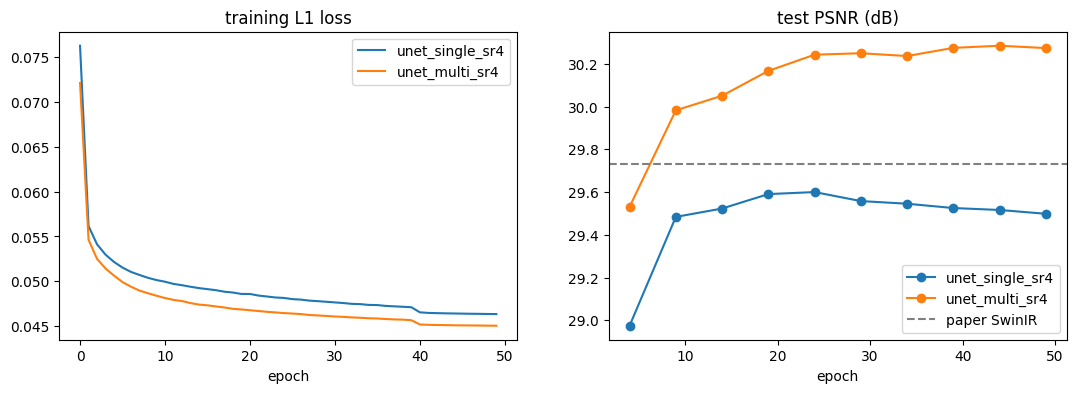

,run,checkpoint,epoch,task,factor,model,psnr,psnr_std,ssim,ssim_std
0,unet_single_sr4,best,24,sr,4,unet_single,29.6002,0.6064,0.7081,0.0224
1,unet_single_sr4,last,49,sr,4,unet_single,29.4983,0.6146,0.7076,0.0224
2,unet_multi_sr4,best,44,sr,4,unet_multi,30.2848,0.6489,0.7256,0.0218
3,unet_multi_sr4,last,49,sr,4,unet_multi,30.2737,0.6506,0.7257,0.0218


In [9]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for cfg in JOBS:
    log = cfg.out_dir / "log.csv"
    if not log.exists():
        continue
    h = pd.read_csv(log)
    ax[0].plot(h.epoch, h.train_l1, label=cfg.run_name)
    if "psnr" in h:
        v = h.dropna(subset=["psnr"]); ax[1].plot(v.epoch, v.psnr, "o-", label=cfg.run_name)
ax[0].set(title="training L1 loss", xlabel="epoch"); ax[0].legend()
ax[1].axhline(PAPER_M4RAW[paper_key(JOBS[0])]["SwinIR"][0], ls="--", c="gray", label="paper SwinIR")
ax[1].set(title="test PSNR (dB)", xlabel="epoch"); ax[1].legend()
plt.show()
if Path("/kaggle/working/results.csv").exists():
    display(pd.read_csv("/kaggle/working/results.csv"))